# Training curves — released policy

Metrics of the training run that produced [`artifacts/policy.keras`](../artifacts/policy.keras), exported from the original Weights & Biases run (`barzksni`, *"MLP - Generalized Cross Map"*) into plain files so they can be inspected without W&B access.

| File | Contents |
|---|---|
| [`barzksni/history.csv`](barzksni/history.csv) | every logged row: train/val losses and metrics every 50 steps, epoch timings |
| [`barzksni/config.json`](barzksni/config.json) | run configuration |
| [`barzksni/summary.json`](barzksni/summary.json) | final values and dataset sampling statistics |

The released policy is the **epoch-10 checkpoint** (dashed line in every plot). Validation metrics come from a temporal hold-out within the training recordings, so they measure offline action prediction, not closed-loop driving ability.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RUN = Path("barzksni")
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
RELEASED_EPOCH = 10

history = pd.read_csv(RUN / "history.csv")
config = json.loads((RUN / "config.json").read_text())
summary = json.loads((RUN / "summary.json").read_text())

epochs = history.dropna(subset=["time/epoch_sec"])
steps_per_epoch = (epochs["step"] / epochs["progress/epoch_completed"]).median()
evals = history.dropna(subset=["val/loss"]).copy()
evals["epoch_float"] = evals["step"] / steps_per_epoch  # 10.0 = end of epoch 10 = released checkpoint

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
COLORS = {"throttle": "#1f77b4", "brake": "#d62728", "steer": "#2ca02c",
          "straight": "#7f7f7f", "left": "#ff7f0e", "right": "#9467bd", "train": "#1f77b4", "val": "#d62728"}

def smooth(series, window=9):
    return series.rolling(window, center=True, min_periods=1).mean()

def mark_release(ax):
    ax.axvline(RELEASED_EPOCH, color="black", linestyle="--", linewidth=1, alpha=0.7)
    ax.set_xlabel("epoch")

def plot_metric(ax, column, label, color, log=False):
    ax.plot(evals["epoch_float"], evals[column], color=color, alpha=0.2, linewidth=0.8)
    ax.plot(evals["epoch_float"], smooth(evals[column]), color=color, linewidth=1.8, label=label)
    if log:
        ax.set_yscale("log")
    mark_release(ax)

## Run overview

In [2]:
overview = {
    "batch size": config["batch_size"],
    "learning rate": config["learning_rate"],
    "stack size (frames)": config["stack_size"],
    "train split": config["train_split"],
    "train windows": summary["sampling/train/windows"],
    "validation windows": summary["sampling/val/windows"],
    "total windows": summary["sampling/manifest_sampled/windows"],
    "epochs completed": int(epochs["progress/epoch_completed"].max()),
    "training steps": int(history["step"].max()),
    "windows seen": int(history["progress/frames_seen"].max()),
    "wall-clock (h)": round(history["time/elapsed_sec"].max() / 3600, 2),
}
direction_mix = {d: round(100 * summary[f"sampling/manifest_sampled/ratio/{d}"], 2) for d in ("straight", "left", "right")}
display(pd.Series(overview, name="value").to_frame())
display(pd.Series(direction_mix, name="% of windows").to_frame())

,value
batch size,409.000
learning rate,0.003
stack size (frames),5.000
train split,0.700
train windows,165777.000
validation windows,71108.000
total windows,236882.000
epochs completed,53.000
training steps,21750.000
windows seen,8881070.000


,% of windows
straight,89.47
left,5.85
right,4.67


## Loss

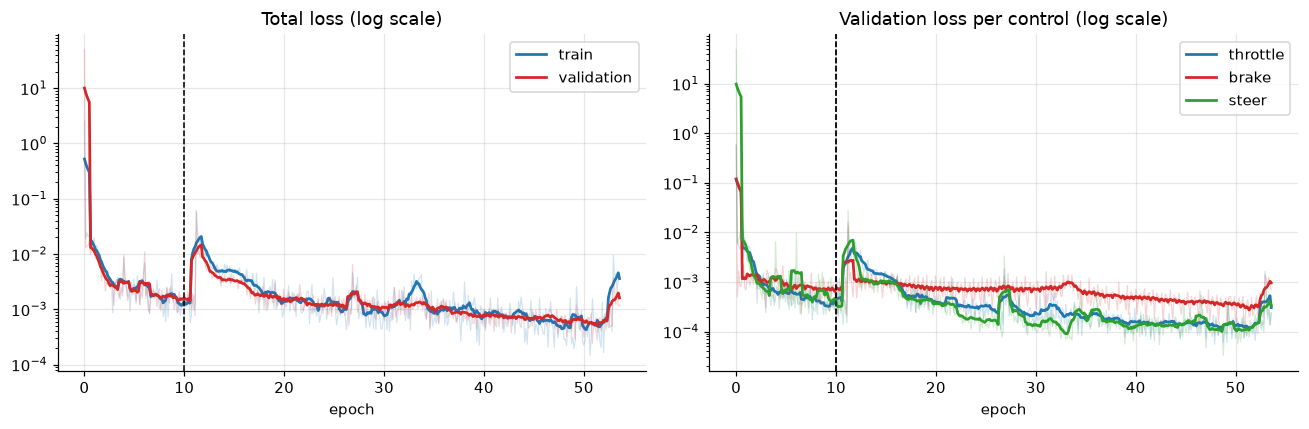

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_metric(axes[0], "train/loss", "train", COLORS["train"], log=True)
plot_metric(axes[0], "val/loss", "validation", COLORS["val"], log=True)
axes[0].set_title("Total loss (log scale)"); axes[0].legend()
for name in ("throttle", "brake", "steer"):
    plot_metric(axes[1], f"val/{name}_loss", name, COLORS[name], log=True)
axes[1].set_title("Validation loss per control (log scale)"); axes[1].legend()
fig.tight_layout(); fig.savefig(FIGURES / "loss.png", bbox_inches="tight", dpi=200); plt.show()

## Validation error per control

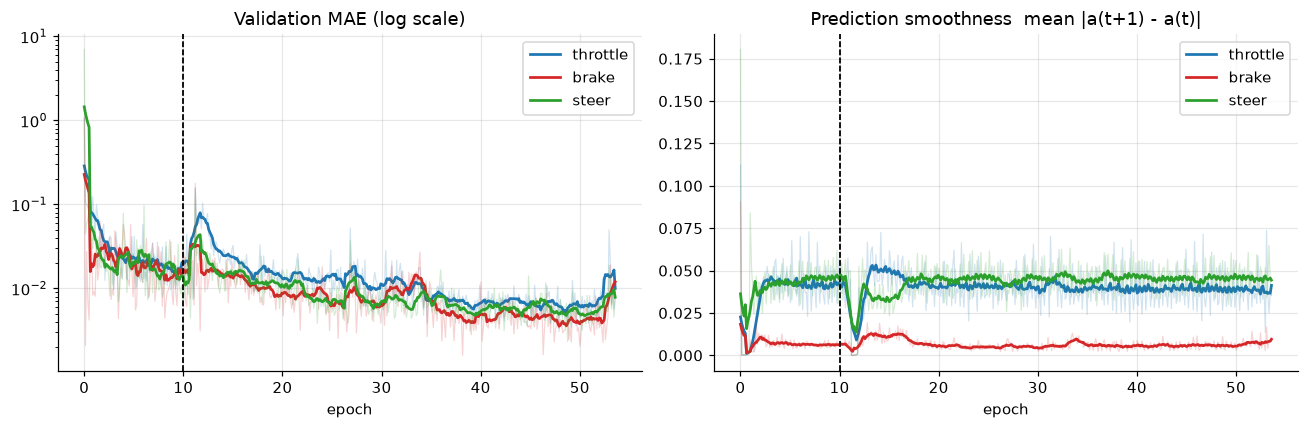

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name in ("throttle", "brake", "steer"):
    plot_metric(axes[0], f"val/mae/{name}", name, COLORS[name], log=True)
    plot_metric(axes[1], f"val/smoothness/{name}", name, COLORS[name])
axes[0].set_title("Validation MAE (log scale)"); axes[0].legend()
axes[1].set_title("Prediction smoothness  mean |a(t+1) - a(t)|"); axes[1].legend()
fig.tight_layout(); fig.savefig(FIGURES / "mae_smoothness.png", bbox_inches="tight", dpi=200); plt.show()

## Turns and directions

Turn detection uses |steer| > 0.1. Left and right turns each make up only ~5–6% of windows, and their validation error stays above straight driving. Shortly after the released epoch-10 checkpoint, training briefly destabilizes (turn F1 drops and turn MSE rises by an order of magnitude) before recovering.

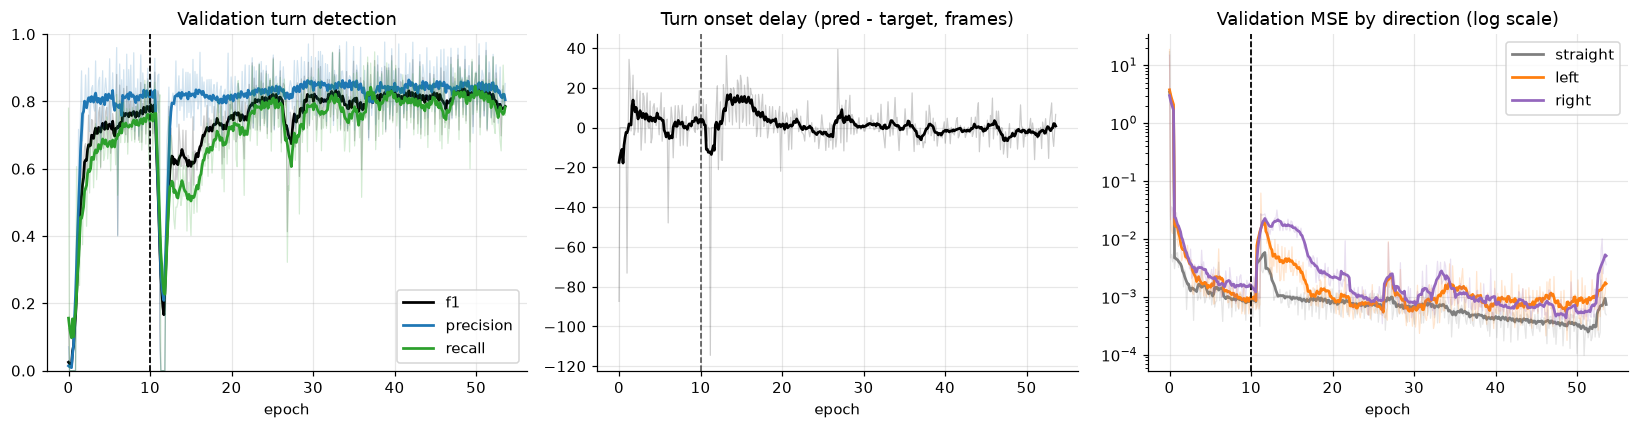

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for metric, color in (("f1", "black"), ("precision", COLORS["throttle"]), ("recall", COLORS["steer"])):
    plot_metric(axes[0], f"val/turn/{metric}", metric, color)
axes[0].set_ylim(0, 1); axes[0].set_title("Validation turn detection"); axes[0].legend()
plot_metric(axes[1], "val/turn/delay_steps", "onset delay (frames)", "black")
axes[1].set_title("Turn onset delay (pred - target, frames)")
for d in ("straight", "left", "right"):
    plot_metric(axes[2], f"val/direction_loss/{d}", d, COLORS[d], log=True)
axes[2].set_title("Validation MSE by direction (log scale)"); axes[2].legend()
fig.tight_layout(); fig.savefig(FIGURES / "turns_directions.png", bbox_inches="tight", dpi=200); plt.show()

## Temporal lag

Mean |prediction(t) − target(t+k)|: the error against the target *k* frames in the future. Error growing with *k* means predictions track the current control; error shrinking with *k* would indicate anticipation of upcoming controls.

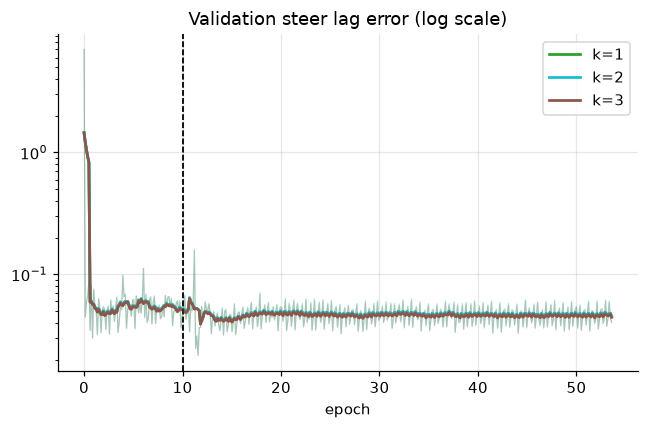

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
for k, color in ((1, "#2ca02c"), (2, "#17becf"), (3, "#8c564b")):
    plot_metric(ax, f"val/lag/steer_k{k}", f"k={k}", color, log=True)
ax.set_title("Validation steer lag error (log scale)"); ax.legend()
fig.tight_layout(); fig.savefig(FIGURES / "lag.png", bbox_inches="tight", dpi=200); plt.show()

## Table 1 (paper)

Epoch 1: last evaluation of the epoch. Other rows: mean over all validation evaluations within the stated epochs.

In [7]:
columns = {"val/loss": "val loss", "val/mae/throttle": "MAE throttle", "val/mae/brake": "MAE brake",
           "val/mae/steer": "MAE steer", "val/turn/f1": "turn F1", "val/direction_loss/straight": "MSE straight",
           "val/direction_loss/left": "MSE left", "val/direction_loss/right": "MSE right"}
table = pd.DataFrame({
    "epoch 1 (end)": evals[evals["progress/epoch"] == 1].iloc[-1][list(columns)],
    "epoch 10 (released)": evals[evals["progress/epoch"] == RELEASED_EPOCH][list(columns)].mean(),
    "epochs 50-53": evals[evals["progress/epoch"].between(50, 53)][list(columns)].mean(),
}).T.rename(columns=columns)
table.map(lambda v: float(f"{v:.3g}"))

,val loss,MAE throttle,MAE brake,MAE steer,turn F1,MSE straight,MSE left,MSE right
epoch 1 (end),0.012600,0.07220,0.00922,0.05600,0.394,0.005790,0.009320,0.013300
epoch 10 (released),0.001530,0.01700,0.01650,0.01330,0.779,0.000837,0.000979,0.001570
epochs 50-53,0.000701,0.00817,0.00429,0.00585,0.817,0.000363,0.000931,0.000826


## Checkpoint timing

The released checkpoint's `metadata.json` records `date_saved` 2026-05-10 22:19:15 UTC; the run started 22:00:32 UTC.

In [8]:
end_of_epoch_10 = epochs.loc[epochs["progress/epoch_completed"] == RELEASED_EPOCH, "time/elapsed_sec"].iloc[0]
print(f"epoch {RELEASED_EPOCH} completed after {end_of_epoch_10:,.0f} s "
      f"-> {pd.Timestamp('2026-05-10 22:00:32') + pd.Timedelta(seconds=end_of_epoch_10)} UTC")

epoch 10 completed after 1,115 s -> 2026-05-10 22:19:07.260000 UTC
